#### Professor Mounya Elhilali, EN.520.645: Audio Signal Processing
# Project 2: Magnitude Spectrum Inversion
Reconstruct a signal with minimal artifacts from magnitude spectrogram

Deliverable 2: code in Python PART TWO
### Harper Strickland
Due Oct. 8, 2026

#### If any of these libraries are not yet available on your system, use pip install or your preferref method prior to running code

In [1]:
# import libraries
import numpy as np
import librosa
import matplotlib
import matplotlib.pyplot as plt

## Analysis

### Compare Spectrograms of Originals and Results

This compares the spectrogram of the original audio file, and spectrograms of the most recently run RTISI and RTISI-LA above.

#### Folder and file names should match part 1

In [ ]:
# input mp3 files
load_folder = 'Audio'
files = ['audio1.mp3', 'audio2.mp3', 'audio3.mp3', 'audio4.mp3',
         'audio5.mp3', 'audio6.mp3', 'audio7.mp3', 'audio8.mp3',
         'audio9.mp3', 'audio10.mp3', 'audio11.mp3', 'audio12.mp3', ]
# folder to save can be same or different from folder where original files are
save_folder = 'Results'

prefix1 = 'RTISI'
prefix2 = 'RTISI-LA'

In [ ]:
# spectrograms comparing results
def spec(file_path):
    y, sr = librosa.load(file_path)
    D = librosa.stft(y)  # STFT of y
    S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

    fig, ax = plt.subplots()
    img = librosa.display.specshow(S_db, ax=ax)
    fig.colorbar(img, ax=ax)
    fig.set_size_inches(35, 9)
    ax.set_title(file_path, fontsize=20)
    plt.show()

In [ ]:
def compare(filename):
    print('Spectrograms: Original, RTISI, RTISI-LA for', filename)
    spec(load_folder + '/' + filename)
    spec(save_folder + '/' + prefix1 + '_' + filename)
    spec(save_folder + '/' + prefix2 + '_' + filename)
    return

In [ ]:
for file in files:
    compare(file)

#### Plot Results for Multiple Runs

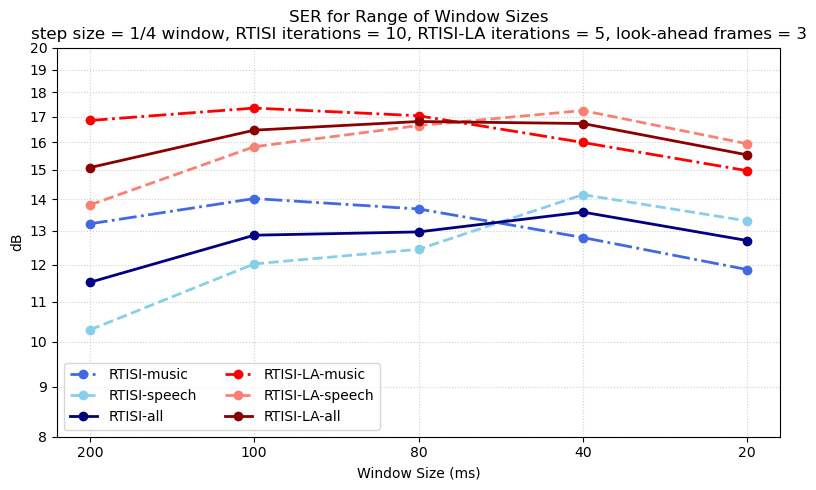

In [2]:
x = ["200", "100", "80", "40", "20"]

data = {
    'RTISI-music':     [13.21, 14.02, 13.68, 12.79, 11.86],
    'RTISI-speech':    [10.29, 12.02, 12.44, 14.15, 13.30],
    'RTISI-all':       [11.51, 12.86, 12.96, 13.58, 12.70],
    'RTISI-LA-music':  [16.85, 17.35, 17.04, 16.00, 14.97],
    'RTISI-LA-speech': [13.81, 15.84, 16.65, 17.25, 15.95],
    'RTISI-LA-all':    [15.08, 16.47, 16.81, 16.73, 15.54],
}
styles = {
    'RTISI-music':     {'color': 'royalblue', 'linestyle': '-.'},
    'RTISI-speech':    {'color': 'skyblue', 'linestyle': '--'},
    'RTISI-all':       {'color': 'navy', 'linestyle': '-'},
    'RTISI-LA-music':  {'color': 'red', 'linestyle': '-.'},
    'RTISI-LA-speech': {'color': 'salmon', 'linestyle': '--'},
    'RTISI-LA-all':    {'color': 'darkred', 'linestyle': '-'},
}

fig, ax = plt.subplots(figsize=(8, 5))

for label, values in data.items():
    ax.plot(x, values, label=label, marker="o", linewidth=2, **styles[label])

ax.set_title('SER for Range of Window Sizes\nstep size = 1/4 window, RTISI iterations = 10, RTISI-LA iterations = 5, look-ahead frames = 3')
ax.set_xlabel('Window Size (ms)')
ax.set_ylabel('dB')
ax.set_yscale('log')  # Log scale for dB

# change y ticks out of scientific notation
ax.set_ylim(8, 20)
ax.set_yticks([8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20])
ax.set_yticklabels(['8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20'])

ax.grid(True, which='both', linestyle=':', alpha=0.6)
ax.legend(ncol=2)
fig.tight_layout()
plt.show()